In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import math
from numbers import Real
import json

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler , LabelEncoder , OneHotEncoder 
from sklearn.compose import ColumnTransformer

import torch
import torch.nn as nn
import joblib

from torch.utils.data import TensorDataset, DataLoader

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score , 
    confusion_matrix
)

# Model parametrelerinin başlangıcı için seed (tam determinism garanti etmez).
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
import time
import random
from pathlib import Path


Device: cuda


In [2]:
df = pd.read_csv("../data/online_shoppers_intention.csv")
df.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [3]:
# Hedef: Revenue=True (1); PageValues dışarıda tutulur.
y = df["Revenue"].astype(int)
X = df.drop(columns=["Revenue", "PageValues"])


In [4]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

In [5]:
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

In [6]:
cat_cols = [
    "Month",
    "VisitorType",
    "Weekend",
    "OperatingSystems",
    "Browser",
    "Region",
    "TrafficType"
]

target = "Revenue"

num_cols = [
    col for col in X_train.columns
    if col not in cat_cols + [target]
]

print("Categorical:", cat_cols)
print("Numerical:", num_cols)

Categorical: ['Month', 'VisitorType', 'Weekend', 'OperatingSystems', 'Browser', 'Region', 'TrafficType']
Numerical: ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'SpecialDay']


In [7]:
one_hot_cols = [col for col in cat_cols if X_train[col].nunique() > 2]
binary_cols = [col for col in cat_cols if col not in one_hot_cols]


In [8]:
# Tüm özellikler açıkça tanımlandı: sadece binary sütunlar passthrough.
tranformer = ColumnTransformer(
    transformers=[
        ("stnd_scaler", StandardScaler(), num_cols),
        ("one_hot", OneHotEncoder(handle_unknown="ignore"), one_hot_cols),
        ("binary", "passthrough", binary_cols),
    ],
    remainder="drop",
)
pipline = Pipeline(steps=[("tranformer", tranformer)])

In [9]:
# Yalnızca train üzerinde fit; validation üzerinde sadece transform.
x_train_tranformer = pipline.fit_transform(X_train)
X_val_tranformer = pipline.transform(X_val)
# Test kümesi son değerlendirmeye kadar kullanılmayacak.

In [10]:
def to_dense(matrix):
    # ColumnTransformer sparse veya dense döndürebilir.
    return matrix.toarray() if hasattr(matrix, "toarray") else np.asarray(matrix)

X_train_tensor = torch.tensor(to_dense(x_train_tranformer), dtype=torch.float32)
X_val_tensor = torch.tensor(to_dense(X_val_tranformer), dtype=torch.float32)
y_train_tensor = torch.tensor(y_train.to_numpy(), dtype=torch.long)
y_val_tensor = torch.tensor(y_val.to_numpy(), dtype=torch.long)



In [11]:
dataset_train = TensorDataset(X_train_tensor , y_train_tensor)

dataloader_train = DataLoader(dataset=dataset_train , batch_size=32 , shuffle=True)

len(dataloader_train)

270

In [12]:
dataset_test = TensorDataset(X_val_tensor , y_val_tensor)

dataloader_test = DataLoader(dataset=dataset_test , batch_size=32 )

len(dataloader_test)

58

In [13]:
class ShopperClassifier(nn.Module):
    def __init__(self, activation="relu", input_dim=73):
        super().__init__()
        if activation == "relu":
            activation_layer = nn.ReLU
        elif activation == "gelu":
            activation_layer = nn.GELU
        else:
            raise ValueError("Activation must be 'relu' or 'gelu'")

        self.linear_layer = nn.Sequential(
            nn.Linear(input_dim, 64),
            activation_layer(),
            nn.Linear(64, 32),
            activation_layer(),
            nn.Linear(32, 2),
        )

    def forward(self, x):
        return self.linear_layer(x) 


In [14]:
model = ShopperClassifier(activation="relu", input_dim=x_train_tranformer.shape[1])

In [15]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(
    params=model.parameters() ,
    lr=0.001
)


In [16]:
def get_positive_probabilities(model, loader):
    model.eval()
    all_probs, all_labels = [], []

    with torch.no_grad():
        for X_batch, y_batch in loader:
            logits = model(X_batch)
            probs = torch.softmax(logits, dim=1)
            all_probs.append(probs[:, 1].cpu())
            all_labels.append(y_batch.cpu())

    return torch.cat(all_probs).numpy(), torch.cat(all_labels).numpy()

In [17]:
def train_model(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    epochs
):

    history = []
    model_device = next(model.parameters()).device

    for epoch in range(epochs):

        model.train()

        running_loss = 0.0
        total_samples = 0

        for x_batch, y_batch in train_loader:

            x_batch = x_batch.to(model_device)
            y_batch = y_batch.to(model_device)

            optimizer.zero_grad()

            outputs = model(x_batch)

            loss = criterion(outputs, y_batch)

            loss.backward()


            optimizer.step()

            batch_size = y_batch.size(0)

            running_loss += loss.item() * batch_size
            total_samples += batch_size

        epoch_loss = running_loss / total_samples

        model.eval()

        val_running_loss = 0.0
        val_total_samples = 0

        all_probabilities = []
        all_labels = []

        with torch.no_grad():

            for x_batch, y_batch in val_loader:

                x_batch = x_batch.to(model_device)
                y_batch = y_batch.to(model_device)

           
                logits = model(x_batch)

            
                loss = criterion(logits, y_batch)

             
                probabilities = torch.softmax(
                    logits,
                    dim=1
                )

               
                all_probabilities.append(
                    probabilities.cpu()
                )

                all_labels.append(
                    y_batch.cpu()
                )

                batch_size = y_batch.size(0)

                val_running_loss += loss.item() * batch_size
                val_total_samples += batch_size


        val_loss = val_running_loss / val_total_samples


        all_probabilities = torch.cat(
            all_probabilities,
            dim=0
        )

        true_labels = torch.cat(
            all_labels
        ).numpy()

        # Pozitif sınıf: Revenue=True
        positive_probabilities = (
            all_probabilities[:, 1].numpy()
        )

        # Average Precision
        val_ap = average_precision_score(
            true_labels,
            positive_probabilities
        )

        # 1. Olasılıklar 0-1 arasında mı?
        range_check = (
            (all_probabilities >= 0) &
            (all_probabilities <= 1)
        ).all().item()

        # 2. İki sınıfın olasılık toplamı 1 mi?
        sum_check = torch.allclose(
            all_probabilities.sum(dim=1),
            torch.ones(
                all_probabilities.shape[0]
            ),
            atol=1e-6
        )

        # 3. Her validation kaydı için olasılık var mı?
        count_check = (
            len(positive_probabilities)
            == len(val_loader.dataset)
        )

        history.append({
            "epoch": epoch + 1,
            "train_loss": epoch_loss,
            "val_loss": val_loss,
            "val_ap": val_ap
        })

        print(
            f"Epoch {epoch + 1}/{epochs} | "
            f"Train Loss: {epoch_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"AP: {val_ap:.4f}"
        )


    print("\n--- Probability Check ---")

    print("0-1 aralığında mı?", range_check)
    print("Olasılıkların toplamı 1 mi?", sum_check)
    print("Her kayıt için olasılık var mı?", count_check)

    print("\nPozitif olasılık sayısı:", len(positive_probabilities))
    print("İlk 10 olasılık:", positive_probabilities[:10])

    return history, positive_probabilities, true_labels

In [18]:
history, positive_probabilities, true_labels = train_model(
    model=model,
    train_loader=dataloader_train,
    val_loader=dataloader_test,
    criterion=criterion,
    optimizer=optimizer,
    epochs=10
)

Epoch 1/10 | Train Loss: 0.4042 | Val Loss: 0.3788 | AP: 0.3348
Epoch 2/10 | Train Loss: 0.3698 | Val Loss: 0.3757 | AP: 0.3338
Epoch 3/10 | Train Loss: 0.3643 | Val Loss: 0.3737 | AP: 0.3352
Epoch 4/10 | Train Loss: 0.3596 | Val Loss: 0.3730 | AP: 0.3311
Epoch 5/10 | Train Loss: 0.3551 | Val Loss: 0.3734 | AP: 0.3338
Epoch 6/10 | Train Loss: 0.3501 | Val Loss: 0.3768 | AP: 0.3403
Epoch 7/10 | Train Loss: 0.3445 | Val Loss: 0.3731 | AP: 0.3626
Epoch 8/10 | Train Loss: 0.3396 | Val Loss: 0.3779 | AP: 0.3497
Epoch 9/10 | Train Loss: 0.3355 | Val Loss: 0.3794 | AP: 0.3552
Epoch 10/10 | Train Loss: 0.3276 | Val Loss: 0.3883 | AP: 0.3351

--- Probability Check ---
0-1 aralığında mı? True
Olasılıkların toplamı 1 mi? True
Her kayıt için olasılık var mı? True

Pozitif olasılık sayısı: 1849
İlk 10 olasılık: [2.5506744e-01 2.4405394e-02 1.5711655e-01 1.9713370e-02 9.5189877e-02
 1.9545591e-01 2.6764053e-01 4.9927086e-01 1.2994258e-04 5.6333899e-01]


In [19]:
def predict_with_threshold(
    probabilities,
    threshold
):
    # Pozitif sınıf olasılıklarını al.
    positive_probabilities = probabilities

    # Threshold ile karşılaştır.
    threshold_results = positive_probabilities >= threshold

    # 0 ve 1 tahminlerini üret.
    predictions = threshold_results.astype(int)

    return predictions

In [20]:
thresholds = [0.50, 0.60, 0.70, 0.80]
results = []

for threshold in thresholds:

    # Daha önce yazdığımız fonksiyonu çağır
    predictions = predict_with_threshold(
        positive_probabilities,
        threshold
    )

    # Metrikler
    accuracy = accuracy_score(true_labels, predictions)

    precision = precision_score(
        true_labels,
        predictions,
        zero_division=0
    )

    recall = recall_score(
        true_labels,
        predictions,
        zero_division=0
    )

    f1 = f1_score(
        true_labels,
        predictions,
        zero_division=0
    )

    # Confusion Matrix
    tn, fp, fn, tp = confusion_matrix(
        true_labels,
        predictions,
        labels=[0, 1]
    ).ravel()

    # Sonuçları sakla
    results.append({
        "Threshold": threshold,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "TP": tp,
        "FP": fp,
        "TN": tn,
        "FN": fn
    })

In [21]:
results_df = pd.DataFrame(results)

print(results_df.to_string(index=False))

 Threshold  Accuracy  Precision   Recall       F1  TP  FP   TN  FN
       0.5  0.828556   0.390071 0.192308 0.257611  55  86 1477 231
       0.6  0.839913   0.428571 0.104895 0.168539  30  40 1523 256
       0.7  0.849108   0.666667 0.048951 0.091205  14   7 1556 272
       0.8  0.846944   1.000000 0.010490 0.020761   3   0 1563 283


In [22]:
from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)
precision_values, recall_values, pr_thresholds = precision_recall_curve(
    true_labels,
    positive_probabilities
)


ap = average_precision_score(
    true_labels,
    positive_probabilities
)

positive_ratio = np.mean(true_labels == 1)

print(f"Average Precision: {ap:.4f}")
print(f"Positive Class Ratio: {positive_ratio:.4f}")
print(f"AP / Positive Ratio: {ap / positive_ratio:.2f}")

Average Precision: 0.3351
Positive Class Ratio: 0.1547
AP / Positive Ratio: 2.17


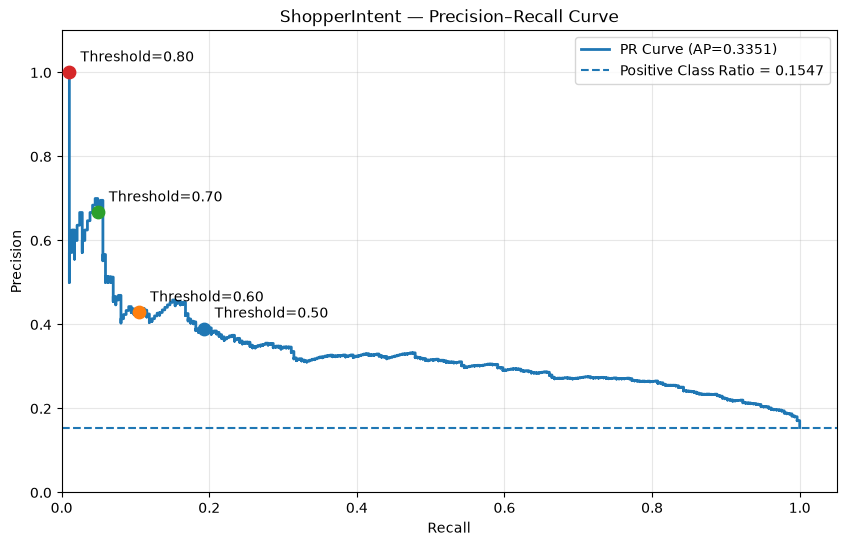

In [23]:
plt.figure(figsize=(10, 6))

plt.step(
    recall_values,
    precision_values,
    where="post",
    linewidth=2,
    label=f"PR Curve (AP={ap:.4f})"
)

plt.axhline(
    y=positive_ratio,
    linestyle="--",
    label=f"Positive Class Ratio = {positive_ratio:.4f}"
)

for _, row in results_df.iterrows():

    recall = row["Recall"]
    precision = row["Precision"]
    threshold = row["Threshold"]

    plt.scatter(
        recall,
        precision,
        s=80,
        zorder=3
    )

    plt.annotate(
        f"Threshold={threshold:.2f}",
        (recall, precision),
        xytext=(8, 8),
        textcoords="offset points"
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("ShopperIntent — Precision–Recall Curve")
plt.xlim(0, 1.05)
plt.ylim(0, 1.10)
plt.grid(alpha=0.3)
plt.legend()
plt.show()

In [24]:
# Mesaj başına maliyet
message_cost = 2

# Hedeflenen kullanıcı sayısı
results_df["Targeted"] = results_df["TP"] + results_df["FP"]

# Toplam kampanya maliyeti
results_df["Total_Cost"] = results_df["Targeted"] * message_cost

# Yanlış alarm maliyeti
results_df["False_Alarm_Cost"] = results_df["FP"] * message_cost

In [25]:
cost_df = results_df[
    [
        "Threshold",
        "Targeted",
        "TP",
        "FP",
        "Total_Cost",
        "False_Alarm_Cost"
    ]
].copy()

print(cost_df.to_string(index=False))

 Threshold  Targeted  TP  FP  Total_Cost  False_Alarm_Cost
       0.5       141  55  86         282               172
       0.6        70  30  40         140                80
       0.7        21  14   7          42                14
       0.8         3   3   0           6                 0


In [26]:
max_target_users = 100

suitable_thresholds = cost_df[
    cost_df["Targeted"] <= max_target_users
]

print(suitable_thresholds.to_string(index=False))

 Threshold  Targeted  TP  FP  Total_Cost  False_Alarm_Cost
       0.6        70  30  40         140                80
       0.7        21  14   7          42                14
       0.8         3   3   0           6                 0


In [27]:
def campaign_decision(
    probability,
    threshold=0.50
):

  
    if isinstance(probability, bool) or not isinstance(probability, Real):
        raise TypeError(
            "Probability must be a numeric value (int or float)."
        )

   
    if isinstance(threshold, bool) or not isinstance(threshold, Real):
        raise TypeError(
            "Threshold must be a numeric value (int or float)."
        )

    if not math.isfinite(probability):
        raise ValueError(
            "Probability must be a finite number."
        )

    if not math.isfinite(threshold):
        raise ValueError(
            "Threshold must be a finite number."
        )


    if not 0 <= probability <= 1:
        raise ValueError(
            "Probability must be between 0 and 1."
        )


    if not 0 <= threshold <= 1:
        raise ValueError(
            "Threshold must be between 0 and 1."
        )

   
    target = bool(probability >= threshold)


    return {
        "probability": float(probability),
        "threshold": float(threshold),
        "target": target
    }

In [28]:
print(campaign_decision(0.75, 0.70))
print(campaign_decision(0.45, 0.70))
print(campaign_decision(0.70, 0.70))
print(campaign_decision(0.75))

{'probability': 0.75, 'threshold': 0.7, 'target': True}
{'probability': 0.45, 'threshold': 0.7, 'target': False}
{'probability': 0.7, 'threshold': 0.7, 'target': True}
{'probability': 0.75, 'threshold': 0.5, 'target': True}


In [29]:

csv_df = results_df.copy()


csv_df["targeted_users"] = csv_df["TP"] + csv_df["FP"]
csv_df["contact_cost"] = csv_df["targeted_users"] * 2
csv_df["false_positive_cost"] = csv_df["FP"] * 2

csv_df = csv_df.rename(columns={
    "Threshold": "threshold",
    "Accuracy": "accuracy",
    "Precision": "precision",
    "Recall": "recall",
    "F1": "f1",
    "TP": "tp",
    "FP": "fp",
    "TN": "tn",
    "FN": "fn"
})

columns = [
    "threshold",
    "accuracy",
    "precision",
    "recall",
    "f1",
    "tp",
    "fp",
    "tn",
    "fn",
    "targeted_users",
    "contact_cost",
    "false_positive_cost"
]

csv_df = csv_df[columns]

Path("reports").mkdir(exist_ok=True)

csv_df.to_csv(
    "reports/threshold_experiments.csv",
    index=False
)

print("CSV başarıyla oluşturuldu!")
print(csv_df.to_string(index=False))

CSV başarıyla oluşturuldu!
 threshold  accuracy  precision   recall       f1  tp  fp   tn  fn  targeted_users  contact_cost  false_positive_cost
       0.5  0.828556   0.390071 0.192308 0.257611  55  86 1477 231             141           282                  172
       0.6  0.839913   0.428571 0.104895 0.168539  30  40 1523 256              70           140                   80
       0.7  0.849108   0.666667 0.048951 0.091205  14   7 1556 272              21            42                   14
       0.8  0.846944   1.000000 0.010490 0.020761   3   0 1563 283               3             6                    0


In [31]:

# Modelin Linear katmanlarını bul
linear_layers = [
    layer
    for layer in model.modules()
    if isinstance(layer, nn.Linear)
]

# Giriş ve çıkış boyutları
input_dim = linear_layers[0].in_features
output_dim = linear_layers[-1].out_features

# ReLU kontrolü
has_relu = any(
    isinstance(layer, nn.ReLU)
    for layer in model.modules()
)

print("Input Features:", input_dim)

Input Features: 73


In [ ]:

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent


models_dir = project_root / "models"
models_dir.mkdir(parents=True, exist_ok=True)

model_path = models_dir / "shopper_mlp.pt"

torch.save(
    model.state_dict(),
    model_path
)

print("Model kaydedildi:", model_path)

Model kaydedildi: /home/pasali/Desktop/Data/AI-Engineer/Hafta-2/ShopperIntent/models/shopper_mlp.pt


In [ ]:

if model_path.is_file():

    file_size = model_path.stat().st_size

    print("Model dosyası mevcut: True")
    print(f"Dosya boyutu: {file_size / 1024:.2f} KB")

else:
    print("Model dosyası bulunamadı!")

Model dosyası mevcut: True
Dosya boyutu: 30.00 KB


In [36]:
model_config = {
    "model": "ShopperClassifier",
    "activation": "ReLU",
    "optimizer": "Adam",
    "input_dim": input_dim,
    "output_dim": output_dim,
    "target": "Revenue",
    "threshold": 0.60
}

config_path = models_dir / "shopper_mlp_config.json"

with open(config_path, "w", encoding="utf-8") as f:
    json.dump(model_config, f, indent=4)

print("Model bilgileri kaydedildi!")
print(model_config)

Model bilgileri kaydedildi!
{'model': 'ShopperClassifier', 'activation': 'ReLU', 'optimizer': 'Adam', 'input_dim': 73, 'output_dim': 2, 'target': 'Revenue', 'threshold': 0.6}


In [42]:
from sklearn.utils.validation import check_is_fitted
project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

models_dir = project_root / "models"
models_dir.mkdir(parents=True, exist_ok=True)

preprocessor_path = models_dir / "preprocessor.joblib"

# Preprocessor daha önce fit edilmiş mi?
check_is_fitted(pipline)

# Kaydet
joblib.dump(
    pipline,
    preprocessor_path
)

print("Preprocessor kaydedildi:", preprocessor_path)
print("Dosya mevcut mu?", preprocessor_path.is_file())

Preprocessor kaydedildi: /home/pasali/Desktop/Data/AI-Engineer/Hafta-2/ShopperIntent/models/preprocessor.joblib
Dosya mevcut mu? True


In [44]:
# Kaydedilmiş preprocessor'ı yükle
loaded_preprocessor = joblib.load(preprocessor_path)

# Eğitim verisinden bir örneği dönüştür
sample = X_train.iloc[:1]

transformed_sample = loaded_preprocessor.transform(sample)

# Preprocessing sonrası özellik sayısı
input_dim = transformed_sample.shape[1]

print("Model Input Dimension:", input_dim)

Model Input Dimension: 73


In [51]:
feature_columns = X_train.columns.tolist()

model_config = {
    "model_name": "ShopperIntent",
    "model_version": "1.0.0",
    "model_type": "PyTorch MLP",
    "activation": "relu",
    "input_dim": input_dim,
    "hidden_layers": [64, 32],
    "output_dim": 2,
    "positive_class": 1,
    "decision_threshold": 0.60,
    "feature_columns": feature_columns
}

config_path = models_dir / "model_config.json"

with open(config_path, "w", encoding="utf-8") as f:
    json.dump(
        model_config,
        f,
        indent=4,
        ensure_ascii=False
    )

print("Model metadata kaydedildi:", config_path)

Model metadata kaydedildi: /home/pasali/Desktop/Data/AI-Engineer/Hafta-2/ShopperIntent/models/model_config.json


In [52]:
print("Preprocessor:", preprocessor_path.is_file())
print("Model Config:", config_path.is_file())

print("Input Dimension:", model_config["input_dim"])
print("Feature Count:", len(model_config["feature_columns"]))

# Kaydettiğimiz model ile preprocessing uyumlu mu?
assert input_dim == linear_layers[0].in_features, (
    "Preprocessing çıktı boyutu modelin giriş boyutuyla uyuşmuyor!"
)

Preprocessor: True
Model Config: True
Input Dimension: 73
Feature Count: 16


In [ ]:
def load_model():

   
    project_root = Path(__file__).resolve().parent.parent

    models_dir = project_root / "models"

    config_path = models_dir / "model_config.json"

    with open(config_path, "r", encoding="utf-8") as f:
        config = json.load(f)

    return config


if __name__ == "__main__":

    config = load_model()

    print("Model Name:", config["model_name"])
    print("Input Dimension:", config["input_dim"])
    print("Hidden Layers:", config["hidden_layers"])
    print("Activation:", config["activation"])
    print("Decision Threshold:", config["decision_threshold"])

In [ ]:
import sys

current_dir = Path.cwd()


if current_dir.name == "notebooks":
    project_root = current_dir.parent
else:
    project_root = current_dir


sys.path.insert(0, str(project_root))


from src.serving import (
    load_model,
    predict_purchase
)

loaded_model, loaded_preprocessor, config = load_model()

session_data = X_val.iloc[0].to_dict()

print("Model başarıyla yüklendi!")
print("Seçilen kullanıcı:", session_data)

Model başarıyla yüklendi!
Seçilen kullanıcı: {'Administrative': 1, 'Administrative_Duration': 0.0, 'Informational': 0, 'Informational_Duration': 0.0, 'ProductRelated': 28, 'ProductRelated_Duration': 2195.580952, 'BounceRates': 0.0, 'ExitRates': 0.021428571, 'SpecialDay': 0.0, 'Month': 'Oct', 'OperatingSystems': 1, 'Browser': 1, 'Region': 3, 'TrafficType': 2, 'VisitorType': 'Returning_Visitor', 'Weekend': False}


In [55]:
# A — Orijinal eğitilmiş model
original_result = predict_purchase(
    session_data,
    model,
    pipline,
    config
)

# B — Diskten yüklenen model
loaded_result = predict_purchase(
    session_data,
    loaded_model,
    loaded_preprocessor,
    config
)

original_probability = original_result["purchase_probability"]
loaded_probability = loaded_result["purchase_probability"]

print("Original Probability:", original_probability)
print("Loaded Probability:", loaded_probability)

Original Probability: 0.25506749749183655
Loaded Probability: 0.25506749749183655


In [56]:
is_consistent = np.isclose(
    original_probability,
    loaded_probability,
    atol=1e-6,
    rtol=0
)

print("Serialization Consistency:", is_consistent)

Serialization Consistency: True
